# Método CASTLE · Variables de opciones: put walls y call walls
**Castle Quant** · Vamos a calcular, a registrar y a poner a prueba el posicionamiento en opciones. Lo que no vamos a hacer es operar el nivel.

## Antes de empezar: ¿qué se sabe y qué no?
En redes vas a ver gráficas con un "call wall" arriba del precio y un "put wall" abajo, presentados como techo y piso. Entonces, antes de usarlos, vamos a separar lo que tiene respaldo de lo que no.

- **Las definiciones son convenciones de proveedores.** No hay un estándar. Un proveedor le dice muro al strike con más gamma. Otro, al strike con más interés abierto. El mismo día pueden dar niveles distintos.
- **Lo que sí tiene respaldo académico:** la relación entre el signo de la gamma agregada de los *dealers* y el régimen de volatilidad. Con gamma negativa, más volatilidad y continuación dentro del día. Con gamma positiva, menos volatilidad y reversión. También el *pinning*: precios que se pegan a un strike cerca del vencimiento.
- **Lo que no tiene respaldo académico:** que el strike del muro sea un soporte o una resistencia que se pueda operar.
- **En cripto el supuesto de signo puede estar al revés.** El cálculo usual supone que el dealer está largo en calls y corto en puts. En bitcoin mucha gente compra calls para especular, y entonces el dealer queda al contrario.

Haz de cuenta que te dicen que en cierta esquina siempre hay trancón. Puede ser. Pero antes de cambiar tu ruta, vas y cuentas los carros. Eso es lo que vamos a hacer acá: **calcular, registrar y probar**. La decisión de usar la variable la toman los datos que tú mismo recojas. ¿Listo?

Lecturas para revisar en la fuente antes de citarlas: Ni, Pearson y Poteshman (2005) sobre *pinning*, Baltussen, Da, Lammers y Martens (2021) sobre gamma y momentum intradía, y Barbon y Buraschi, *Gamma Fragility*. Acá no citamos cifras de esos trabajos porque no las verificamos en el texto original.

In [1]:
# Método CASTLE: una variable nueva entra por las mismas letras de siempre
# C · Captura          -> la foto de la cadena de opciones (secciones 1 a 5)
# A · Alfa             -> de la foto a una variable con fecha y hora (sección 6)
# L · Libre de sesgos  -> la prueba contra el azar y contra un placebo (sección 7)
# S · Simulación       -> la variable como filtro de la estrategia de 12 horas (sección 8)

### Primero, el entorno

In [2]:
# Solamente en Google Colab: traemos las librerías del método (research.py, models.py), el modelo entrenado y las velas de 12 horas
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('research.py'):
    !git clone --depth 1 https://github.com/JuliRey2000/metodo_CASTLE_castlequant.com.git
    %cd metodo_CASTLE_castlequant.com

In [3]:
# Si abriste el notebook desde la carpeta castle_labs/, vamos a subir a la raíz del repositorio (ahí están research.py y los datos)
if not os.path.exists('research.py') and os.path.exists(os.path.join('..', 'research.py')):
    os.chdir('..')
# Le decimos a Python dónde queda la raíz, para poder importar research y models
sys.path.insert(0, os.getcwd())

In [4]:
# Las librerías de datos y de números
import polars as pl                                     # DataFrames para series financieras
import numpy as np                                      # Cálculo numérico
import matplotlib.pyplot as plt                         # Gráficas
import re                                               # Lectura del nombre de cada opción
import tempfile                                         # Carpeta temporal para el ejemplo de guardado
from datetime import datetime, timedelta, timezone      # Manejo de fechas

# Las librerías del método
import research                                         # Estilo de las gráficas, velas, retornos y simulación
import models                                           # El modelo lineal del Notebook 1

# De dónde salen los datos
import requests                                         # Llamada a la API pública de Deribit

In [5]:
# Los colores de las gráficas (los mismos de research.py, más un rojo y un verde para marcar niveles)
AZUL, DORADO, TEXTO, GRIS = research.AZUL, research.DORADO, research.TEXTO, research.GRIS
ROJO, VERDE = '#f58b88', '#3fcf9f'

In [6]:
# Para escribir los precios con punto de miles en las gráficas
def miles(x):
    return f'{x:,.0f}'.replace(',', '.')

In [7]:
# Para que las tablas de Polars se vean completas
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(100)
pl.Config.set_tbl_cols(-1);  # Mostrar todas las columnas sin truncar

---
# 1. Captura: la foto de la cadena de opciones
¿Qué es una cadena de opciones? No deja de ser más que la lista de todos los contratos abiertos. Cada uno con su vencimiento, su strike, su tipo (call o put), cuántos contratos hay abiertos (*open interest*) y la volatilidad implícita con la que cotiza.

Haz de cuenta que es la carta de un restaurante: todos los platos, con su precio y con cuánta gente pidió cada uno.

Vamos a tener dos fuentes:
- `'sintetica'`: una cadena inventada, pero con cara de real. Funciona sin internet. Es la que trae el notebook.
- `'deribit'`: la cadena real de bitcoin, de la API pública de Deribit (sin claves).

In [8]:
# De dónde sale la foto: 'sintetica' (sin internet) o 'deribit' (cadena real)
FUENTE = 'sintetica'
# La moneda de las opciones en Deribit
MONEDA = 'BTC'
# El tamaño del contrato: en Deribit una opción de BTC es sobre 1 BTC
TAMANO_CONTRATO = 1.0

### Leer el nombre de una opción
En Deribit el nombre lo dice todo. `BTC-27DEC26-100000-C` es una call (`C`) de bitcoin con strike 100.000 que vence el 27 de diciembre de 2026. Los vencimientos son a las 08:00 UTC.

In [9]:
# Los meses tal como los escribe Deribit
MESES = {'JAN': 1, 'FEB': 2, 'MAR': 3, 'APR': 4, 'MAY': 5, 'JUN': 6, 'JUL': 7, 'AUG': 8, 'SEP': 9, 'OCT': 10, 'NOV': 11, 'DEC': 12}
# Cómo viene el nombre: MONEDA-DÍA MES AÑO-STRIKE-TIPO
PATRON = re.compile(r'^([A-Z]+)-(\d{1,2})([A-Z]{3})(\d{2})-(\d+)-([CP])$')

def leer_instrumento(nombre):
    """'BTC-27DEC26-100000-C' -> (vencimiento a las 08:00 UTC, strike, tipo). Devuelve None si el nombre no tiene esa forma."""
    partes = PATRON.match(str(nombre))
    if partes is None or partes.group(3) not in MESES:
        return None
    _, dia, mes, anio, strike, tipo = partes.groups()
    return datetime(2000 + int(anio), MESES[mes], int(dia), 8), float(strike), tipo

In [10]:
# Un ejemplito
leer_instrumento('BTC-27DEC26-100000-C')

(datetime.datetime(2026, 12, 27, 8, 0), 100000.0, 'C')

### De la respuesta de la API a una tabla
La función que sigue recibe la lista de contratos y devuelve la tablita con la que trabaja el resto del notebook. Sirve igual para la cadena real y para la sintética.

In [11]:
# Los campos que vamos a usar de cada contrato.
# OJO: estos nombres salen de la documentación de Deribit tal como la recordamos. No se comprobaron contra una respuesta real
# donde se armó este notebook (no había acceso a Deribit). Por eso la función revisa y te avisa clarito.
CAMPOS = ['instrument_name', 'open_interest', 'mark_iv', 'underlying_price']

def armar_cadena(filas, ahora):
    """Convierte la lista de contratos en una tabla: timestamp, instrumento, vencimiento, strike, tipo, oi, iv, subyacente."""
    if not filas:
        raise ValueError('La lista de contratos llegó vacía')
    # Si falta un campo, te mostramos los que sí llegaron para que corrijas el nombre
    faltan = [c for c in CAMPOS if c not in filas[0]]
    if faltan:
        raise KeyError(f'Faltan los campos {faltan}. Campos recibidos: {sorted(filas[0].keys())}. Ajusta la lista CAMPOS')
    registros = []
    for f in filas:
        partes = leer_instrumento(f['instrument_name'])
        # Nos saltamos los nombres que vienen distinto y los contratos sin dato
        if partes is None or any(f[c] is None for c in CAMPOS):
            continue
        vencimiento, strike, tipo = partes
        registros.append({'timestamp': ahora, 'instrumento': f['instrument_name'], 'vencimiento': vencimiento, 'strike': strike,
                          'tipo': tipo, 'oi': float(f['open_interest']), 'iv': float(f['mark_iv']), 'subyacente': float(f['underlying_price'])})
    if not registros:
        raise ValueError('Ningún contrato tiene la forma MONEDA-DÍAMESAÑO-STRIKE-TIPO. Revisa un instrument_name de la respuesta')
    cadena = pl.DataFrame(registros)
    # La volatilidad implícita tiene que quedar en decimal (0,45 y no 45). Si llega en porcentaje, la dividimos entre 100
    if cadena['iv'].median() > 3:
        cadena = cadena.with_columns(pl.col('iv') / 100)
    # Solamente los contratos que aún no vencen y que traen volatilidad válida
    return cadena.filter((pl.col('vencimiento') > ahora) & (pl.col('iv') > 0)).sort('vencimiento', 'strike', 'tipo')

### Fuente real: Deribit
Una sola llamada trae el resumen de todas las opciones. No pide clave.

In [12]:
URL_DERIBIT = 'https://www.deribit.com/api/v2/public/get_book_summary_by_currency'

def descargar_deribit(moneda='BTC'):
    """Lista de contratos de opciones de la moneda, tal como la entrega la API pública de Deribit."""
    respuesta = requests.get(URL_DERIBIT, params={'currency': moneda, 'kind': 'option'}, timeout=30)
    respuesta.raise_for_status()
    cuerpo = respuesta.json()
    # La lista debería venir en la llave 'result' (no se comprobó contra una respuesta real)
    if 'result' not in cuerpo:
        raise KeyError(f"La respuesta no trae 'result'. Llaves recibidas: {sorted(cuerpo.keys())}")
    return cuerpo['result']

### Fuente sintética
Para practicar sin internet vamos a armar una cadena inventada alrededor de un precio de 90.000:
- 6 vencimientos: uno diario, dos semanales, dos mensuales y uno trimestral.
- Strikes cada 1.000 en los vencimientos cercanos y cada 5.000 en los lejanos.
- Una **sonrisa de volatilidad**: las opciones lejos del precio cotizan con más volatilidad, y las puts un poquito más que las calls.
- Interés abierto amontonado en los strikes redondos, con las calls cargadas arriba del precio y las puts abajo.

La semilla fija hace que siempre salga la misma cadena. **Estos números no son del mercado.**

In [13]:
# Los segundos de un año: para pasar el tiempo al vencimiento a años
SEGUNDOS_ANIO = 365 * 24 * 3600

In [14]:
def cadena_sintetica(spot=90_000.0, ahora=datetime(2026, 11, 27, 9), semilla=8):
    """Lista de contratos inventada, con la misma forma que esperamos de Deribit."""
    rng = np.random.default_rng(semilla)
    nombres_mes = {numero: nombre for nombre, numero in MESES.items()}
    # Cada vencimiento: fecha, paso entre strikes, ancho del rango, interés abierto total (BTC) y volatilidad en el dinero
    vencimientos = [
        (datetime(2026, 11, 28, 8), 1_000, 0.10,  4_000, 0.42),     # diario
        (datetime(2026, 12, 4, 8),  1_000, 0.15, 18_000, 0.44),     # semanal
        (datetime(2026, 12, 11, 8), 1_000, 0.20, 12_000, 0.45),     # semanal
        (datetime(2026, 12, 25, 8), 1_000, 0.25, 90_000, 0.47),     # mensual
        (datetime(2027, 1, 29, 8),  5_000, 0.45, 60_000, 0.50),     # mensual
        (datetime(2027, 3, 26, 8),  5_000, 0.60, 80_000, 0.52),     # trimestral
    ]
    filas = []
    for vencimiento, paso, ancho, oi_total, vol_atm in vencimientos:
        # Cuánto falta para el vencimiento, en años
        T = (vencimiento - ahora).total_seconds() / SEGUNDOS_ANIO
        # Los strikes de ese vencimiento
        strikes = np.arange(np.ceil(spot * (1 - ancho) / paso) * paso, spot * (1 + ancho) + 1, paso)
        # Qué tan lejos está cada strike del precio, en desviaciones estándar
        m = np.clip(np.log(strikes / spot) / (vol_atm * np.sqrt(T)), -3, 3)
        # La sonrisa: más volatilidad lejos del precio, y un poquito más del lado de las puts
        iv = vol_atm * (1 - 0.05 * m + 0.04 * m ** 2)
        # Los strikes redondos jalan más interés abierto
        redondo = np.where(strikes % 10_000 == 0, 2.5, np.where(strikes % 5_000 == 0, 2.0, 1.0))
        for tipo, centro, parte in [('C', 1.2, 0.58), ('P', -1.2, 0.42)]:
            # Las calls cargadas arriba del precio (centro +1,2) y las puts abajo (centro -1,2), con alguito de ruido
            peso = np.exp(-0.5 * ((m - centro) / 0.8) ** 2) * redondo * rng.lognormal(0, 0.35, len(strikes))
            oi = np.round(oi_total * parte * peso / peso.sum(), 1)
            for k, o, v in zip(strikes, oi, iv):
                nombre = f'BTC-{vencimiento.day}{nombres_mes[vencimiento.month]}{vencimiento:%y}-{int(k)}-{tipo}'
                # mark_iv va en porcentaje, como suponemos que lo entrega Deribit
                filas.append({'instrument_name': nombre, 'open_interest': float(o), 'mark_iv': float(100 * v), 'underlying_price': float(spot)})
    return filas

### Tomar la foto
Ya tenemos con qué. Entonces vamos a tomar la foto. ¿Listo?

In [15]:
if FUENTE == 'sintetica':
    # La hora de la foto sintética: 09:00 UTC, una hora después del vencimiento diario
    ahora = datetime(2026, 11, 27, 9)
    filas = cadena_sintetica(spot=90_000.0, ahora=ahora)
elif FUENTE == 'deribit':
    # La hora real de la foto, en UTC. Para que lo tengas en cuenta: esta rama no se ejecutó donde se armó el notebook
    ahora = datetime.now(timezone.utc).replace(tzinfo=None, microsecond=0)
    filas = descargar_deribit(MONEDA)
else:
    raise ValueError("FUENTE debe ser 'sintetica' o 'deribit'")
# Un contrato tal como llega
filas[0]

{'instrument_name': 'BTC-28NOV26-81000-C',
 'open_interest': 0.0,
 'mark_iv': 63.41999999999999,
 'underlying_price': 90000.0}

In [16]:
# La tablita de trabajo: una fila por contrato
cadena = armar_cadena(filas, ahora)
cadena

timestamp,instrumento,vencimiento,strike,tipo,oi,iv,subyacente
datetime[μs],str,datetime[μs],f64,str,f64,f64,f64
2026-11-27 09:00:00,"""BTC-28NOV26-81000-C""",2026-11-28 08:00:00,81000.0,"""C""",0.0,0.6342,90000.0
2026-11-27 09:00:00,"""BTC-28NOV26-81000-P""",2026-11-28 08:00:00,81000.0,"""P""",27.6,0.6342,90000.0
2026-11-27 09:00:00,"""BTC-28NOV26-82000-C""",2026-11-28 08:00:00,82000.0,"""C""",0.0,0.6342,90000.0
2026-11-27 09:00:00,"""BTC-28NOV26-82000-P""",2026-11-28 08:00:00,82000.0,"""P""",34.9,0.6342,90000.0
2026-11-27 09:00:00,"""BTC-28NOV26-83000-C""",2026-11-28 08:00:00,83000.0,"""C""",0.0,0.6342,90000.0
…,…,…,…,…,…,…,…
2026-11-27 09:00:00,"""BTC-26MAR27-130000-P""",2027-03-26 08:00:00,130000.0,"""P""",89.4,0.519709,90000.0
2026-11-27 09:00:00,"""BTC-26MAR27-135000-C""",2027-03-26 08:00:00,135000.0,"""C""",3164.0,0.523291,90000.0
2026-11-27 09:00:00,"""BTC-26MAR27-135000-P""",2027-03-26 08:00:00,135000.0,"""P""",25.7,0.523291,90000.0


In [17]:
# El precio del subyacente: tomamos el del vencimiento más cercano, que es el que más se parece al precio de contado
spot = cadena['subyacente'][0]
spot

90000.0

In [18]:
# Un resumen por vencimiento: cuántos contratos hay y cuánto interés abierto en calls y en puts (en BTC)
cadena.group_by('vencimiento').agg(
    pl.len().alias('contratos'),
    pl.col('oi').filter(pl.col('tipo') == 'C').sum().alias('oi_calls'),
    pl.col('oi').filter(pl.col('tipo') == 'P').sum().alias('oi_puts'),
).sort('vencimiento')

vencimiento,contratos,oi_calls,oi_puts
datetime[μs],u32,f64,f64
2026-11-28 08:00:00,38,2320.1,1679.9
2026-12-04 08:00:00,54,10440.0,7559.8
2026-12-11 08:00:00,74,6960.1,5040.1
2026-12-25 08:00:00,90,52199.9,37800.4
2027-01-29 08:00:00,34,34800.1,25200.1
2027-03-26 08:00:00,42,46400.2,33600.0


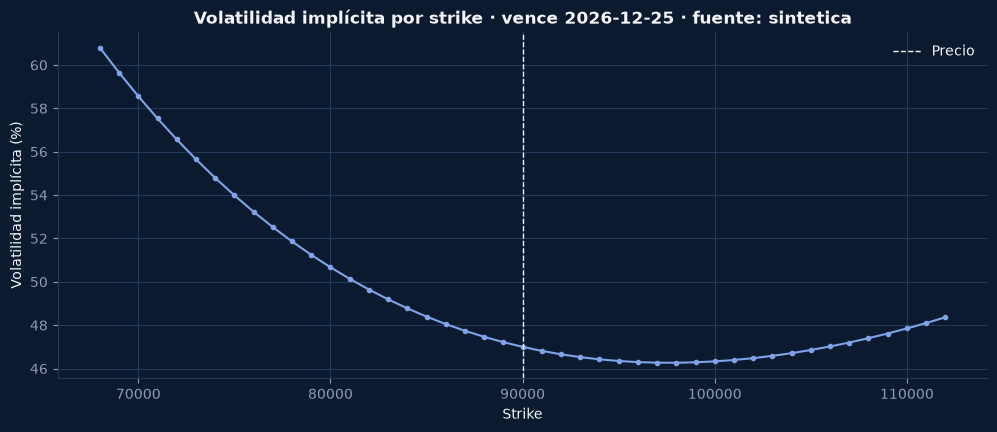

In [19]:
# Vamos a ver la sonrisa de volatilidad del vencimiento mensual más cercano
mensual = cadena.filter((pl.col('vencimiento') == cadena.filter(pl.col('vencimiento') > ahora + timedelta(days=20))['vencimiento'].min()) & (pl.col('tipo') == 'C'))
plt.plot(mensual['strike'].to_numpy(), 100 * mensual['iv'].to_numpy(), lw=1.5, marker='o', ms=3)
plt.axvline(spot, color=TEXTO, lw=1, ls='--', label='Precio')
plt.title(f'Volatilidad implícita por strike · vence {mensual["vencimiento"][0]:%Y-%m-%d} · fuente: {FUENTE}')
plt.xlabel('Strike')
plt.ylabel('Volatilidad implícita (%)')
plt.legend()
plt.show()

---
# 2. Griegas: gamma
¿Qué es la gamma? Vamos por partes. La **delta** de una opción dice cuánto cambia su precio cuando el subyacente se mueve 1 dólar. Y la **gamma** no deja de ser más que cuánto cambia esa delta.

Haz de cuenta que vas en un carro. La delta es la velocidad y la gamma es el acelerador. El que cubre una opción tiene que ajustar su cobertura cada vez que la delta cambia. Entonces la gamma mide **cuánto le toca comprar o vender** cuando el precio se mueve.

Con el modelo de Black-Scholes y tasa de interés 0, esta es la formulita:

$$\Gamma = \frac{\varphi(d_1)}{S\,\sigma\,\sqrt{T}}, \qquad d_1 = \frac{\ln(S/K) + \tfrac{1}{2}\sigma^2 T}{\sigma\sqrt{T}}$$

$S$ es el precio, $K$ el strike, $\sigma$ la volatilidad implícita, $T$ el tiempo al vencimiento en años y $\varphi$ la campana normal. La gamma de una call y la de una put con el mismo strike y el mismo vencimiento es la misma. ¿Listo?

In [20]:
def gamma_bs(S, K, T, sigma):
    """Gamma de Black-Scholes con tasa 0. Sirve para calls y para puts."""
    d1 = (np.log(S / K) + 0.5 * sigma ** 2 * T) / (sigma * np.sqrt(T))
    # La campana normal evaluada en d1
    phi = np.exp(-0.5 * d1 ** 2) / np.sqrt(2 * np.pi)
    return phi / (S * sigma * np.sqrt(T))

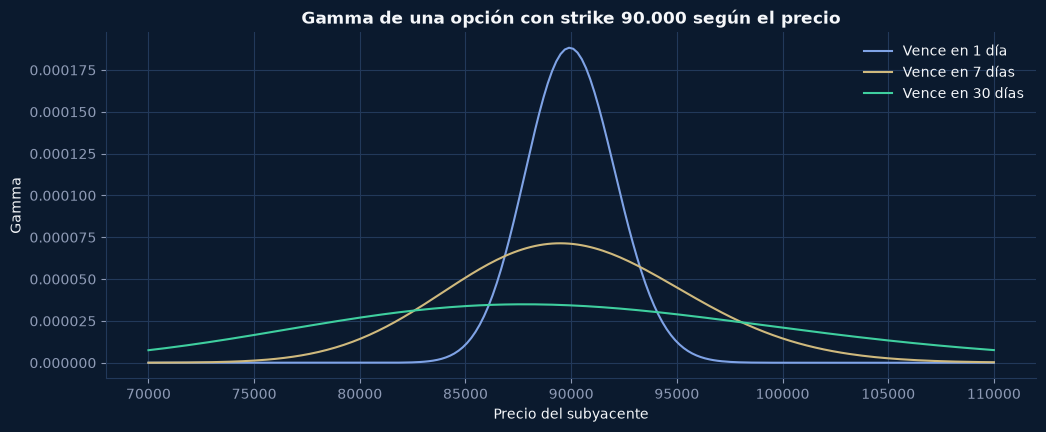

In [21]:
# Mira que la gamma se amontona cerca del strike y crece cuando falta poquito para el vencimiento
precios = np.linspace(70_000, 110_000, 200)
plt.plot(precios, gamma_bs(precios, 90_000, 1 / 365, 0.45), lw=1.5, label='Vence en 1 día')
plt.plot(precios, gamma_bs(precios, 90_000, 7 / 365, 0.45), lw=1.5, label='Vence en 7 días')
plt.plot(precios, gamma_bs(precios, 90_000, 30 / 365, 0.45), lw=1.5, color=VERDE, label='Vence en 30 días')
plt.title('Gamma de una opción con strike 90.000 según el precio')
plt.xlabel('Precio del subyacente')
plt.ylabel('Gamma')
plt.legend()
plt.show()

---
# 3. Exposición gamma (GEX)
Ya tenemos la gamma de un contrato. Ahora vamos a sumar la de todos. Para cada contrato:

$$\text{GEX} = \text{signo} \times \Gamma \times \text{OI} \times \text{tamaño del contrato} \times S^2 \times 0{,}01$$

¿Qué sale de ahí? Dólares: cuánto tendría que comprar o vender el que cubre ese contrato **si el precio se mueve 1 %**.

### El supuesto detrás del signo
Mira que el interés abierto dice cuántos contratos hay. **No dice quién los tiene.** Es como ver un parqueadero lleno: sabes cuántos carros hay, no de quién son. Entonces, para ponerle signo, toca suponer algo:

- La convención usual: los clientes **venden calls** (para cobrar prima) y **compran puts** (para protegerse). Entonces el dealer queda largo en calls (`signo_calls = +1`) y corto en puts (`signo_puts = −1`).
- Con gamma positiva el dealer vende cuando sube y compra cuando baja: frena el movimiento. Con gamma negativa hace lo contrario: lo empuja.

¿Por qué es frágil ese supuesto?
- Si en un strike la mitad de los clientes compró y la otra mitad vendió, la exposición real del dealer es casi cero, pero la fórmula muestra un número enorme.
- En cripto mucha gente **compra** calls. Ahí el signo de las calls estaría al revés.
- Una parte grande de las opciones sobre bitcoin se negocia fuera de Deribit (opciones sobre ETF en Estados Unidos). Esta foto no las ve.

Por eso los dos signos son parámetros. Cuando pruebes la variable, prueba también la convención contraria. ¿Listo?

In [22]:
# La convención de signo: +1 si suponemos que el dealer está largo, -1 si suponemos que está corto
signo_calls = +1
signo_puts = -1

In [23]:
def calcular_gex(cadena, spot, signo_calls=+1, signo_puts=-1, tamano=TAMANO_CONTRATO):
    """Agrega a la cadena el tiempo al vencimiento (T), la gamma y la exposición gamma en dólares por un movimiento de 1 %."""
    # Cuánto falta para el vencimiento, en años
    cadena = cadena.with_columns(((pl.col('vencimiento') - pl.col('timestamp')).dt.total_seconds() / SEGUNDOS_ANIO).alias('T'))
    # La gamma de cada contrato al precio que le pasamos
    gamma = gamma_bs(spot, cadena['strike'].to_numpy(), cadena['T'].to_numpy(), cadena['iv'].to_numpy())
    # El signo según el tipo de opción
    signo = np.where(cadena['tipo'].to_numpy() == 'C', signo_calls, signo_puts)
    gex = signo * gamma * cadena['oi'].to_numpy() * tamano * spot ** 2 * 0.01
    return cadena.with_columns(pl.Series('gamma', gamma), pl.Series('gex', gex))

In [24]:
# La GEX de cada contrato
cadena_gex = calcular_gex(cadena, spot, signo_calls, signo_puts)
cadena_gex

timestamp,instrumento,vencimiento,strike,tipo,oi,iv,subyacente,T,gamma,gex
datetime[μs],str,datetime[μs],f64,str,f64,f64,f64,f64,f64,f64
2026-11-27 09:00:00,"""BTC-28NOV26-81000-C""",2026-11-28 08:00:00,81000.0,"""C""",0.0,0.6342,90000.0,0.002626,6.7495e-7,0.0
2026-11-27 09:00:00,"""BTC-28NOV26-81000-P""",2026-11-28 08:00:00,81000.0,"""P""",27.6,0.6342,90000.0,0.002626,6.7495e-7,-1508.919519
2026-11-27 09:00:00,"""BTC-28NOV26-82000-C""",2026-11-28 08:00:00,82000.0,"""C""",0.0,0.6342,90000.0,0.002626,0.000002,0.0
2026-11-27 09:00:00,"""BTC-28NOV26-82000-P""",2026-11-28 08:00:00,82000.0,"""P""",34.9,0.6342,90000.0,0.002626,0.000002,-6080.630122
2026-11-27 09:00:00,"""BTC-28NOV26-83000-C""",2026-11-28 08:00:00,83000.0,"""C""",0.0,0.6342,90000.0,0.002626,0.000006,0.0
…,…,…,…,…,…,…,…,…,…,…
2026-11-27 09:00:00,"""BTC-26MAR27-130000-P""",2027-03-26 08:00:00,130000.0,"""P""",89.4,0.519709,90000.0,0.325913,0.000008,-59660.611124
2026-11-27 09:00:00,"""BTC-26MAR27-135000-C""",2027-03-26 08:00:00,135000.0,"""C""",3164.0,0.523291,90000.0,0.325913,0.000007,1.8335e6
2026-11-27 09:00:00,"""BTC-26MAR27-135000-P""",2027-03-26 08:00:00,135000.0,"""P""",25.7,0.523291,90000.0,0.325913,0.000007,-14892.936918


In [25]:
# La GEX neta total, en millones de dólares por cada 1 % de movimiento
net_gex = cadena_gex['gex'].sum()
net_gex / 1e6

92.56146088476619

### Agregar por strike
Vamos a sumar todos los vencimientos de cada strike, con las calls y las puts por separado.

In [26]:
def gex_por_strike(cadena_gex):
    """Una fila por strike: GEX de calls, GEX de puts, GEX neta e interés abierto de cada lado."""
    es_call, es_put = pl.col('tipo') == 'C', pl.col('tipo') == 'P'
    return cadena_gex.group_by('strike').agg(
        pl.col('gex').filter(es_call).sum().alias('gex_calls'),
        pl.col('gex').filter(es_put).sum().alias('gex_puts'),
        pl.col('gex').sum().alias('gex_neta'),
        pl.col('oi').filter(es_call).sum().alias('oi_calls'),
        pl.col('oi').filter(es_put).sum().alias('oi_puts'),
    ).sort('strike')

In [27]:
por_strike = gex_por_strike(cadena_gex)
por_strike

strike,gex_calls,gex_puts,gex_neta,oi_calls,oi_puts
f64,f64,f64,f64,f64,f64
40000.0,8.973758,-56139.830017,-56130.856259,0.1,625.6
45000.0,40.815401,-198580.530269,-198539.714868,0.3,1459.6
50000.0,366.406707,-880107.4771,-879741.070393,1.8,4483.8
55000.0,3721.134832,-1.0616e6,-1.0579e6,12.6,3867.7
60000.0,14632.047695,-3.0478e6,-3.0332e6,35.5,8117.6
…,…,…,…,…,…
120000.0,6.3253e6,-135087.668131,6.1902e6,7765.8,160.7
125000.0,6.0285e6,-58568.658988,5.9699e6,8878.8,78.3
130000.0,5.2265e6,-61468.334539,5.1651e6,8929.6,93.3


---
# 4. Los muros
¿Qué es un muro? No deja de ser más que el strike donde más se amontona algo. La cuestión es que circulan dos definiciones con el mismo nombre:

| | Call wall | Put wall |
|---|---|---|
| **Por gamma** | Strike donde las calls concentran más GEX | Strike donde las puts concentran más GEX |
| **Por interés abierto** | Strike con más contratos de calls abiertos | Strike con más contratos de puts abiertos |

Con la convención usual, el call wall por gamma es el strike con la GEX de calls más positiva y el put wall el de la GEX de puts más negativa. Usamos el valor absoluto para que la función sirva también si cambias los signos. Mira que el muro dice **dónde** está la gamma, no de qué lado está el dealer.

In [28]:
def muros(por_strike):
    """Call wall y put wall con las dos definiciones: por gamma y por interés abierto."""
    def strike_del_maximo(columna):
        return por_strike['strike'][int(por_strike[columna].abs().arg_max())]
    return {
        'call_wall': strike_del_maximo('gex_calls'),        # por gamma
        'put_wall': strike_del_maximo('gex_puts'),          # por gamma
        'call_wall_oi': strike_del_maximo('oi_calls'),      # por interés abierto
        'put_wall_oi': strike_del_maximo('oi_puts'),        # por interés abierto
    }

In [29]:
niveles = muros(por_strike)
niveles

{'call_wall': 95000.0,
 'put_wall': 85000.0,
 'call_wall_oi': 110000.0,
 'put_wall_oi': 80000.0}

In [30]:
# ¿Las dos definiciones dan el mismo strike?
pl.DataFrame({
    'muro': ['call wall', 'put wall'],
    'por_gamma': [niveles['call_wall'], niveles['put_wall']],
    'por_interes_abierto': [niveles['call_wall_oi'], niveles['put_wall_oi']],
}).with_columns((pl.col('por_gamma') == pl.col('por_interes_abierto')).alias('coinciden'))

muro,por_gamma,por_interes_abierto,coinciden
str,f64,f64,bool
"""call wall""",95000.0,110000.0,false
"""put wall""",85000.0,80000.0,false


Cuando no coinciden, la razón casi siempre es el tiempo. El strike con más contratos suele estar en un vencimiento lejano, donde la gamma es pequeñita. El strike con más gamma suele estar en un vencimiento cercano, aunque tenga menos contratos.

Entonces dos proveedores honestos pueden publicar muros distintos el mismo día. ¿Listo?

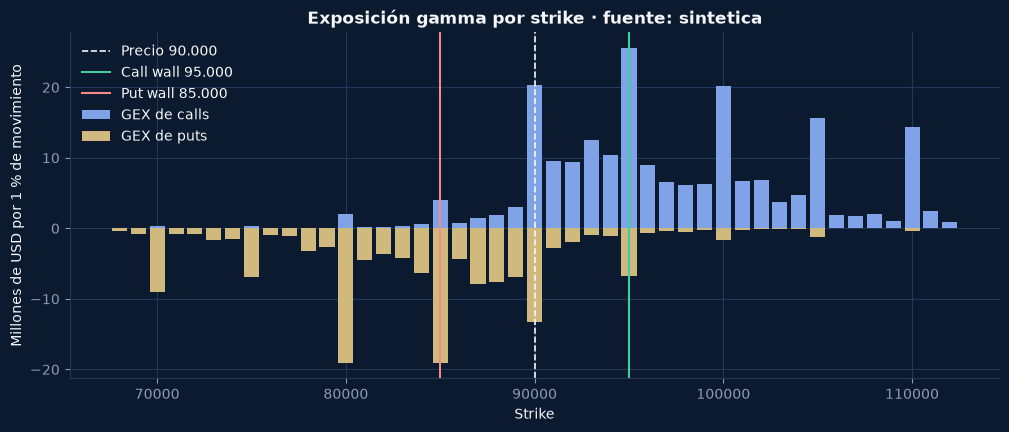

In [31]:
# La GEX por strike, con el precio y los dos muros por gamma (solamente strikes a menos de 25 % del precio)
cerca = por_strike.filter((pl.col('strike') > spot * 0.75) & (pl.col('strike') < spot * 1.25))
ancho = 0.8 * cerca['strike'].diff().min()
plt.bar(cerca['strike'].to_numpy(), cerca['gex_calls'].to_numpy() / 1e6, width=ancho, color=AZUL, zorder=2, label='GEX de calls')
plt.bar(cerca['strike'].to_numpy(), cerca['gex_puts'].to_numpy() / 1e6, width=ancho, color=DORADO, zorder=2, label='GEX de puts')
plt.axvline(spot, color=TEXTO, lw=1.2, ls='--', label=f'Precio {miles(spot)}')
plt.axvline(niveles['call_wall'], color=VERDE, lw=1.5, label=f'Call wall {miles(niveles["call_wall"])}')
plt.axvline(niveles['put_wall'], color=ROJO, lw=1.5, label=f'Put wall {miles(niveles["put_wall"])}')
plt.title(f'Exposición gamma por strike · fuente: {FUENTE}')
plt.xlabel('Strike')
plt.ylabel('Millones de USD por 1 % de movimiento')
plt.legend()
plt.show()

---
# 5. Gamma flip y max pain
### Gamma flip
El **gamma flip** no deja de ser más que el precio en el que la GEX neta total cruza cero. Por encima, según la convención, los dealers frenan el movimiento. Por debajo, lo empujan.

Imagínate el termostato de la casa. Por encima de cierta temperatura enfría, por debajo calienta. Lo que buscamos es esa temperatura.

No se busca mirando la gráfica anterior. La gamma de cada opción cambia cuando el precio cambia. Entonces toca **recalcular toda la cadena** en una rejilla de precios hipotéticos y ver dónde la suma cambia de signo.

In [32]:
def perfil_gex(cadena, rejilla, signo_calls=+1, signo_puts=-1):
    """GEX neta total recalculada en cada precio hipotético de la rejilla."""
    return np.array([calcular_gex(cadena, s, signo_calls, signo_puts)['gex'].sum() for s in rejilla])

def gamma_flip(rejilla, perfil, spot):
    """Precio donde la GEX neta cruza cero (interpolado). Si hay varios cruces, el más cercano al precio; si no hay, nan."""
    cruces = np.where(np.sign(perfil[:-1]) != np.sign(perfil[1:]))[0]
    if len(cruces) == 0:
        return float('nan')
    # Una regla de tres entre los dos puntos de la rejilla que rodean cada cruce (interpolación lineal)
    ceros = rejilla[cruces] - perfil[cruces] * (rejilla[cruces + 1] - rejilla[cruces]) / (perfil[cruces + 1] - perfil[cruces])
    return float(ceros[np.argmin(np.abs(ceros - spot))])

In [33]:
# La rejilla de precios hipotéticos: desde 30 % abajo hasta 30 % arriba del precio
rejilla = np.linspace(spot * 0.7, spot * 1.3, 121)
perfil = perfil_gex(cadena, rejilla, signo_calls, signo_puts)
flip = gamma_flip(rejilla, perfil, spot)
flip

86605.23600847292

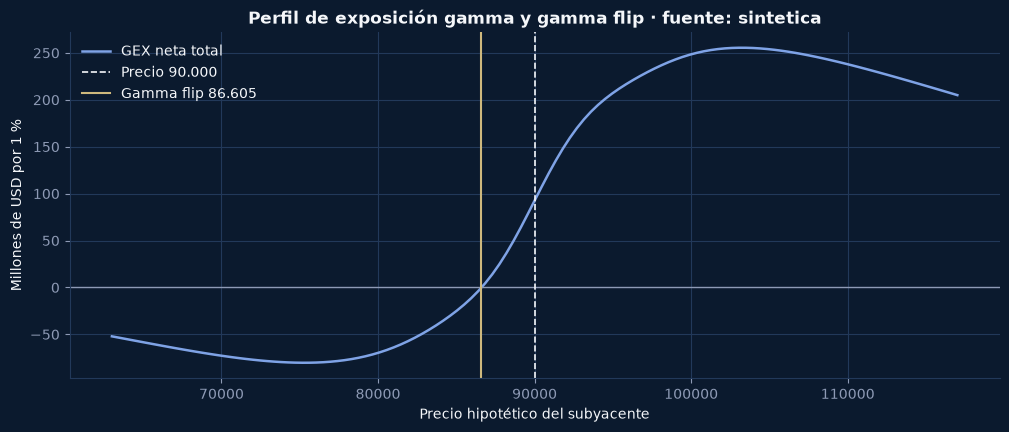

In [34]:
# El perfil de la GEX neta: qué exposición habría en cada precio, con la cadena de hoy
plt.plot(rejilla, perfil / 1e6, lw=1.8, label='GEX neta total')
plt.axhline(0, color=GRIS, lw=1)
plt.axvline(spot, color=TEXTO, lw=1.2, ls='--', label=f'Precio {miles(spot)}')
plt.axvline(flip, color=DORADO, lw=1.5, label=f'Gamma flip {miles(flip)}')
plt.title(f'Perfil de exposición gamma y gamma flip · fuente: {FUENTE}')
plt.xlabel('Precio hipotético del subyacente')
plt.ylabel('Millones de USD por 1 %')
plt.legend()
plt.show()

### Max pain
El **max pain** es el precio de vencimiento en el que los compradores de opciones cobrarían menos en total. Se calcula por vencimiento y solamente usa el interés abierto.

Es **un cálculo, no un mecanismo**: nadie garantiza que el precio vaya hacia allá. Lo dejamos como nivel de comparación. ¿Listo?

In [35]:
def max_pain(cadena_de_un_vencimiento):
    """Strike de liquidación que minimiza el pago total a los compradores de opciones de ese vencimiento."""
    strikes = cadena_de_un_vencimiento['strike'].to_numpy()
    oi = cadena_de_un_vencimiento['oi'].to_numpy()
    es_call = cadena_de_un_vencimiento['tipo'].to_numpy() == 'C'
    candidatos = np.unique(strikes)
    # El pago total si el precio liquida en cada candidato: las calls pagan por encima de su strike y las puts por debajo
    pagos = [(oi * np.where(es_call, np.maximum(p - strikes, 0), np.maximum(strikes - p, 0))).sum() for p in candidatos]
    return float(candidatos[int(np.argmin(pagos))])

In [36]:
# El max pain del vencimiento con más interés abierto
vencimiento_mayor = cadena.group_by('vencimiento').agg(pl.col('oi').sum()).sort('oi', descending=True)['vencimiento'][0]
nivel_max_pain = max_pain(cadena.filter(pl.col('vencimiento') == vencimiento_mayor))
vencimiento_mayor, nivel_max_pain

(datetime.datetime(2026, 12, 25, 8, 0), 90000.0)

---
# 6. De la foto a la variable
Hasta acá tenemos una foto. Y un modelo no come fotos: necesita **una fila por fecha**, con números que se puedan comparar entre días.

Mira que un muro en 95.000 no significa lo mismo con el precio en 90.000 un día tranquilo que un día agitado. Es como decir "queda a 5 kilómetros": no es lo mismo a pie que en carro. Por eso vamos a medir las distancias en **volatilidades diarias**:

$$\text{dist} = \frac{\text{nivel} - S}{S \cdot \sigma_{\text{diaria}}}$$

Una distancia de 2 quiere decir "a dos días típicos de movimiento".

In [37]:
def variables_opciones(snapshot, spot, vol_diaria, signo_calls=+1, signo_puts=-1):
    """De la foto de la cadena a una fila de variables, lista para registrar."""
    # La GEX de cada contrato y la agregada por strike
    cadena_gex = calcular_gex(snapshot, spot, signo_calls, signo_puts)
    net_gex = float(cadena_gex['gex'].sum())
    niveles = muros(gex_por_strike(cadena_gex))
    # El gamma flip sobre la rejilla de precios hipotéticos
    rejilla = np.linspace(spot * 0.7, spot * 1.3, 121)
    flip = gamma_flip(rejilla, perfil_gex(snapshot, rejilla, signo_calls, signo_puts), spot)
    # Qué tan lejos queda un nivel del precio, en volatilidades diarias
    def distancia(nivel):
        return (nivel - spot) / (spot * vol_diaria)
    return pl.DataFrame({
        'timestamp': [snapshot['timestamp'][0]],
        'spot': [float(spot)],
        'net_gex': [net_gex],
        'signo_gex': [int(np.sign(net_gex))],
        'call_wall': [niveles['call_wall']],
        'put_wall': [niveles['put_wall']],
        'gamma_flip': [flip],
        'dist_call_wall': [distancia(niveles['call_wall'])],
        'dist_put_wall': [distancia(niveles['put_wall'])],
        'dist_flip': [distancia(flip)],
    })

### La volatilidad diaria
La vamos a medir con las velas de 12 horas del repositorio: desviación estándar de los últimos 30 días, llevada de 12 horas a 1 día con $\sqrt{2}$. Si tu archivo de velas está viejo, actualízalo con el Notebook 1 o usa tu propia medida.

In [38]:
# Las velas de 12 horas del repositorio y su retorno logarítmico
velas_reales = pl.read_csv('BTCUSDT_12h_ohlc.csv', try_parse_dates=True).sort('datetime')
velas_reales = research.add_log_return_features(velas_reales, 'close', 1)
# Las últimas 60 velas (30 días): volatilidad de 12 horas por raíz de 2
vol_diaria = velas_reales['close_log_return'].tail(60).std() * np.sqrt(2)
vol_diaria

np.float64(0.014998115144335251)

In [39]:
# La fila de hoy
fila = variables_opciones(cadena, spot, vol_diaria, signo_calls, signo_puts)
fila

timestamp,spot,net_gex,signo_gex,call_wall,put_wall,gamma_flip,dist_call_wall,dist_put_wall,dist_flip
datetime[μs],f64,f64,i64,f64,f64,f64,f64,f64,f64
2026-11-27 09:00:00,90000.0,9.2561e7,1,95000.0,85000.0,86605.236008,3.704169,-3.704169,-2.514956


### Guardar la foto todos los días
Las fuentes gratuitas solamente entregan **la foto de hoy**. No hay historia gratis. Entonces la historia la construyes tú, guardando una filita diaria. Es como pesarse: una sola pesada no dice nada, la serie sí.

Dos reglas:
1. **Hora fija.** Toma la foto siempre a la misma hora, después del vencimiento de las 08:00 UTC de Deribit (por ejemplo, 09:00 UTC, 4 a. m. en Colombia). Antes de esa hora la cadena aún incluye contratos que están por desaparecer.
2. **La fila solamente sirve para velas posteriores.** Una foto tomada a las 09:00 UTC no puede explicar una vela que abrió antes. Usarla así es sesgo de anticipación (*look-ahead*). En este notebook la fila del día se usa a partir del día siguiente.

Y para que lo tengas en cuenta: en Google Colab los archivos se borran cuando se cierra la sesión. Si trabajas ahí, descarga el archivo cada día y vuelve a subirlo antes de correr, o corre el notebook en tu computador. ¿Listo?

In [40]:
# El archivo donde se va acumulando tu registro diario
RUTA_DIARIO = os.path.join('castle_labs', 'datos', 'opciones_diario.csv')

def guardar_snapshot(fila, ruta=RUTA_DIARIO):
    """Agrega la fila al registro diario. Si ya hay una fila de esa fecha, no la repite."""
    carpeta = os.path.dirname(ruta)
    if carpeta:
        os.makedirs(carpeta, exist_ok=True)
    existe = os.path.exists(ruta)
    if existe:
        # Las fechas que ya están registradas
        registradas = pl.read_csv(ruta, try_parse_dates=True)['timestamp'].dt.date().to_list()
        if fila['timestamp'][0].date() in registradas:
            print(f'Ya hay una fila del {fila["timestamp"][0]:%Y-%m-%d} en {ruta}: no se agrega otra')
            return
    # Se escribe al final del archivo. El encabezado, solamente la primera vez
    with open(ruta, 'ab') as archivo:
        fila.write_csv(archivo, include_header=not existe)
    print(f'Fila del {fila["timestamp"][0]:%Y-%m-%d %H:%M} UTC guardada en {ruta}')

In [41]:
if FUENTE == 'deribit':
    # La foto real sí va a tu registro
    guardar_snapshot(fila)
else:
    # La foto sintética la guardamos en una carpeta temporal para ver cómo queda, sin ensuciar tu registro real
    ruta_ejemplo = os.path.join(tempfile.mkdtemp(), 'opciones_diario_ejemplo.csv')
    guardar_snapshot(fila, ruta_ejemplo)
    # Y si lo intentas otra vez el mismo día, la fila no se duplica
    guardar_snapshot(fila, ruta_ejemplo)
    display(pl.read_csv(ruta_ejemplo, try_parse_dates=True))

Fila del 2026-11-27 09:00 UTC guardada en /tmp/tmpko_mkdwh/opciones_diario_ejemplo.csv
Ya hay una fila del 2026-11-27 en /tmp/tmpko_mkdwh/opciones_diario_ejemplo.csv: no se agrega otra


timestamp,spot,net_gex,signo_gex,call_wall,put_wall,gamma_flip,dist_call_wall,dist_put_wall,dist_flip
datetime[μs],f64,f64,i64,f64,f64,f64,f64,f64,f64
2026-11-27 09:00:00,90000.0,9.2561e7,1,95000.0,85000.0,86605.236008,3.704169,-3.704169,-2.514956


---
# 7. ¿Cómo se prueba?
## AVISO: DESDE AQUÍ LOS DATOS SON SIMULADOS
Aún no tienes historia registrada. Entonces, para aprender la prueba, vamos a usar una **historia inventada** de 500 días. Lo que salga en esta sección **no dice nada sobre el mercado**. Solamente muestra cómo se hace la prueba, para que la repitas con tu propio registro.

Lo bueno de inventarla es que sabemos exactamente qué tiene adentro:
- **Volatilidad:** el día siguiente a una GEX negativa, la volatilidad es 25 % mayor. Ese efecto lo pusimos a propósito, para ver si la prueba lo encuentra.
- **Muros:** cada día el call wall y el put wall se ponen en un strike redondo a una distancia al azar entre 0,5 y 3 volatilidades diarias. **El precio no sabe dónde están.** El efecto de los muros es cero por construcción.

Haz de cuenta que escondemos una moneda en un cuarto y dejamos el otro vacío. Si el detector pita donde está la moneda y se queda callado en el vacío, el detector sirve.

In [42]:
def historia_sintetica(dias=500, semilla=1, efecto_vol=0.25, precio_inicial=60_000.0):
    """Historia inventada: velas de 12 horas y de 1 día, y una fila diaria de variables de opciones tomada a las 09:00 UTC."""
    rng = np.random.default_rng(semilla)
    # 1. El signo de la GEX: cambia poquito de un día a otro (9 de cada 10 días repite)
    signo = np.ones(dias)
    for t in range(1, dias):
        signo[t] = signo[t - 1] if rng.random() < 0.9 else -signo[t - 1]
    # 2. La volatilidad diaria base, con sus propias rachas, que no dependen de la GEX
    log_vol = np.zeros(dias)
    for t in range(1, dias):
        log_vol[t] = 0.95 * log_vol[t - 1] + rng.normal(0, 0.08)
    vol_base = 0.025 * np.exp(log_vol)
    # 3. El efecto que ponemos a propósito: si la GEX de ayer fue negativa, hoy la volatilidad sube
    signo_ayer = np.concatenate([[1.0], signo[:-1]])
    vol_dia = vol_base * np.where(signo_ayer < 0, 1 + efecto_vol, 1.0)
    # 4. El precio hora a hora: retornos al azar con la volatilidad de cada día. Nada más mueve el precio
    retornos = rng.standard_normal((dias, 24)) * (vol_dia[:, None] / np.sqrt(24))
    cierre = precio_inicial * np.exp(np.cumsum(retornos.ravel()))
    apertura = np.concatenate([[precio_inicial], cierre[:-1]])
    inicio = datetime(2026, 11, 27) - timedelta(days=dias)
    horas = pl.DataFrame({
        'datetime': [inicio + timedelta(hours=h) for h in range(dias * 24)],
        'open': apertura, 'high': np.maximum(apertura, cierre), 'low': np.minimum(apertura, cierre), 'close': cierre,
    })
    # 5. La volatilidad que se conocía cada día: desviación de los retornos diarios de los 30 días anteriores
    retorno_diario = np.diff(np.log(cierre.reshape(dias, 24)[:, -1]), prepend=np.nan)
    vol_conocida = np.array([np.std(retorno_diario[t - 30:t], ddof=1) if t > 30 else vol_base[t] for t in range(dias)])
    # 6. La foto diaria de las 09:00 UTC: el precio de ese momento y los muros puestos al azar, sin mirar el futuro
    spot = apertura.reshape(dias, 24)[:, 9]
    call_wall = np.ceil(spot * (1 + rng.uniform(0.5, 3.0, dias) * vol_conocida) / 1_000) * 1_000
    put_wall = np.floor(spot * (1 - rng.uniform(0.5, 3.0, dias) * vol_conocida) / 1_000) * 1_000
    diario = pl.DataFrame({
        'timestamp': [inicio + timedelta(days=d, hours=9) for d in range(dias)],
        'spot': spot,
        'net_gex': signo * rng.lognormal(np.log(2e8), 0.5, dias),
        'signo_gex': signo.astype(int),
        'call_wall': call_wall,
        'put_wall': put_wall,
        'gamma_flip': spot * (1 - signo * rng.uniform(0.01, 0.06, dias)),
    })
    # Las velas de 12 horas y de 1 día, con la misma función de agregación del método
    return research.timeseries(horas, '12h', research.OHLC_AGGS), research.timeseries(horas, '1d', research.OHLC_AGGS), diario

In [43]:
# La historia SIMULADA: velas de 12 horas, velas diarias y registro diario de opciones
velas_12h_sim, velas_1d_sim, diario_sim = historia_sintetica()
diario_sim

timestamp,spot,net_gex,signo_gex,call_wall,put_wall,gamma_flip
datetime[μs],f64,f64,i64,f64,f64,f64
2025-07-15 09:00:00,58881.452458,3.0231e8,1,64000.0,57000.0,57179.724716
2025-07-16 09:00:00,57014.403996,2.1565e8,1,59000.0,54000.0,54444.544259
2025-07-17 09:00:00,56395.04742,-8.3477e8,-1,60000.0,52000.0,58932.832594
2025-07-18 09:00:00,56268.60094,-2.2283e8,-1,58000.0,54000.0,58519.193544
2025-07-19 09:00:00,55102.190562,1.1592e8,1,59000.0,51000.0,51876.512709
…,…,…,…,…,…,…
2026-11-22 09:00:00,44043.441128,2.2086e8,1,47000.0,42000.0,43189.835612
2026-11-23 09:00:00,43216.009359,-7.6522e7,-1,46000.0,41000.0,43710.528339
2026-11-24 09:00:00,44855.262922,-4.4489e8,-1,47000.0,42000.0,47253.439546


### Preparar los datos como lo harías con tu registro
Desde acá el código es el mismo que vas a usar con `castle_labs/datos/opciones_diario.csv` y velas reales.

In [44]:
# Las velas diarias: retorno logarítmico, su valor absoluto y la volatilidad de los 30 días anteriores (sin incluir el día)
velas_1d_sim = research.add_log_return_features(velas_1d_sim, 'close', 1).with_columns(
    pl.col('datetime').dt.date().alias('fecha'),
    pl.col('close_log_return').abs().alias('retorno_abs'),
    pl.col('close_log_return').rolling_std(30).shift(1).alias('vol_diaria'),
)

In [45]:
# Las distancias en volatilidades diarias, con la volatilidad que se conocía el día de la foto
diario_sim = diario_sim.with_columns(pl.col('timestamp').dt.date().alias('fecha')).join(
    velas_1d_sim.select('fecha', 'vol_diaria'), on='fecha',
).with_columns(
    ((pl.col('call_wall') - pl.col('spot')) / (pl.col('spot') * pl.col('vol_diaria'))).alias('dist_call_wall'),
    ((pl.col('put_wall') - pl.col('spot')) / (pl.col('spot') * pl.col('vol_diaria'))).alias('dist_put_wall'),
    ((pl.col('gamma_flip') - pl.col('spot')) / (pl.col('spot') * pl.col('vol_diaria'))).alias('dist_flip'),
)

In [46]:
# La regla contra el sesgo de anticipación: la fila del día t se junta con la vela del día t + 1
prueba = diario_sim.with_columns((pl.col('fecha') + pl.duration(days=1)).alias('fecha_vela')).join(
    velas_1d_sim.select(pl.col('fecha').alias('fecha_vela'), 'high', 'low', 'close', 'retorno_abs'), on='fecha_vela',
).drop_nulls().sort('fecha')
prueba

timestamp,spot,net_gex,signo_gex,call_wall,put_wall,gamma_flip,fecha,vol_diaria,dist_call_wall,dist_put_wall,dist_flip,fecha_vela,high,low,close,retorno_abs
datetime[μs],f64,f64,i64,f64,f64,f64,date,f64,f64,f64,f64,date,f64,f64,f64,f64
2025-08-15 09:00:00,57380.106325,-1.8081e8,-1,60000.0,55000.0,59758.649772,2025-08-15,0.028119,1.623767,-1.475151,1.474182,2025-08-16,60203.420838,55376.084054,60203.420838,0.070642
2025-08-16 09:00:00,55653.631252,-1.2456e8,-1,61000.0,53000.0,56960.964755,2025-08-16,0.028236,3.402228,-1.688671,0.831938,2025-08-17,61525.615765,59988.858791,60296.975524,0.001553
2025-08-17 09:00:00,60846.797981,-3.2882e8,-1,63000.0,56000.0,62456.43875,2025-08-17,0.02918,1.21272,-2.7298,0.906577,2025-08-18,64755.735639,60060.646975,64202.290956,0.062757
2025-08-18 09:00:00,62033.929586,-2.5857e8,-1,68000.0,59000.0,63819.060822,2025-08-18,0.028914,3.326173,-1.691461,0.995237,2025-08-19,64202.290956,61579.529175,62390.663595,0.028623
2025-08-19 09:00:00,63800.079678,-1.3570e8,-1,70000.0,60000.0,64672.049255,2025-08-19,0.030907,3.144175,-1.92714,0.442203,2025-08-20,64887.226281,62390.663595,64887.226281,0.039235
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-11-21 09:00:00,43465.490753,1.7115e8,1,46000.0,42000.0,42032.421857,2026-11-21,0.02785,2.093765,-1.210646,-1.183862,2026-11-22,44831.308878,43850.631889,44041.66798,0.002649
2026-11-22 09:00:00,44043.441128,2.2086e8,1,47000.0,42000.0,43189.835612,2026-11-22,0.028124,2.386904,-1.649721,-0.689137,2026-11-23,44390.79163,43216.009359,44244.535874,0.004596
2026-11-23 09:00:00,43216.009359,-7.6522e7,-1,46000.0,41000.0,43710.528339,2026-11-23,0.025586,2.517777,-2.004108,0.447232,2026-11-24,45782.4537,42785.928153,42931.17952,0.030134


## Prueba A: ¿la GEX negativa anticipa más movimiento?
**Hipótesis, escrita antes de mirar:** cuando el signo de la GEX es negativo, el retorno absoluto del día siguiente es mayor.

La medida es sencilla: retorno absoluto promedio tras GEX negativa, menos el promedio tras GEX positiva.

In [47]:
# El retorno absoluto promedio del día siguiente, según el signo de la GEX (datos SIMULADOS)
prueba.group_by('signo_gex').agg(pl.len().alias('dias'), pl.col('retorno_abs').mean().alias('retorno_abs_promedio')).sort('signo_gex')

signo_gex,dias,retorno_abs_promedio
i64,u32,f64
-1,234,0.022412
1,234,0.017598


### ¿Y si fue suerte? La prueba de permutaciones
Es la misma idea del Notebook 2. Barajamos la señal muchas veces y miramos qué diferencia sale **sin saber nada**. Si la diferencia real queda en la cola de las barajadas, es complicado explicarla por azar.

Imagínate una baraja. Si después de barajar mil veces casi nunca sale una mano tan buena como la tuya, tu mano no fue suerte.

Un cambio importante: acá barajamos **por bloques** de 10 días. El signo de la GEX y la volatilidad vienen en rachas. Si barajamos día por día rompemos esas rachas, y cualquier coincidencia entre dos rachas parece un hallazgo.

In [48]:
def diferencia_por_signo(signo, valor):
    """Promedio del valor con signo negativo menos el promedio con signo positivo."""
    return valor[signo < 0].mean() - valor[signo > 0].mean()

def permutar_por_bloques(x, tam_bloque, rng):
    """Baraja el orden de bloques consecutivos de `tam_bloque` datos; dentro de cada bloque el orden se conserva."""
    bloques = [x[i:i + tam_bloque] for i in range(0, len(x), tam_bloque)]
    return np.concatenate([bloques[i] for i in rng.permutation(len(bloques))])

def prueba_de_regimen(signo, valor, no_permutaciones=1000, tam_bloque=10, semilla=42, dos_colas=False):
    """Diferencia observada, las diferencias con el signo barajado por bloques y el valor p."""
    rng = np.random.default_rng(semilla)
    observada = diferencia_por_signo(signo, valor)
    al_azar = np.array([diferencia_por_signo(permutar_por_bloques(signo, tam_bloque, rng), valor) for _ in range(no_permutaciones)])
    if dos_colas:
        # Si no anunciamos dirección: cuentan las barajadas con una diferencia igual o mayor en tamaño, hacia cualquier lado
        extremas = (np.abs(al_azar) >= abs(observada)).sum()
    else:
        # Si la hipótesis ya traía dirección: cuentan las barajadas con una diferencia igual o mayor que la observada
        extremas = (al_azar >= observada).sum()
    # El valor p: qué fracción de las barajadas salió tan extrema como lo observado
    return observada, al_azar, (1 + extremas) / (1 + no_permutaciones)

In [49]:
# Vamos a barajar el signo 1.000 veces, en bloques de 10 días
signo = prueba['signo_gex'].to_numpy()
retorno_abs = prueba['retorno_abs'].to_numpy()
diferencia, diferencias_al_azar, valor_p = prueba_de_regimen(signo, retorno_abs, no_permutaciones=1000, tam_bloque=10)
diferencia, valor_p

(np.float64(0.004813979989263913), np.float64(0.005994005994005994))

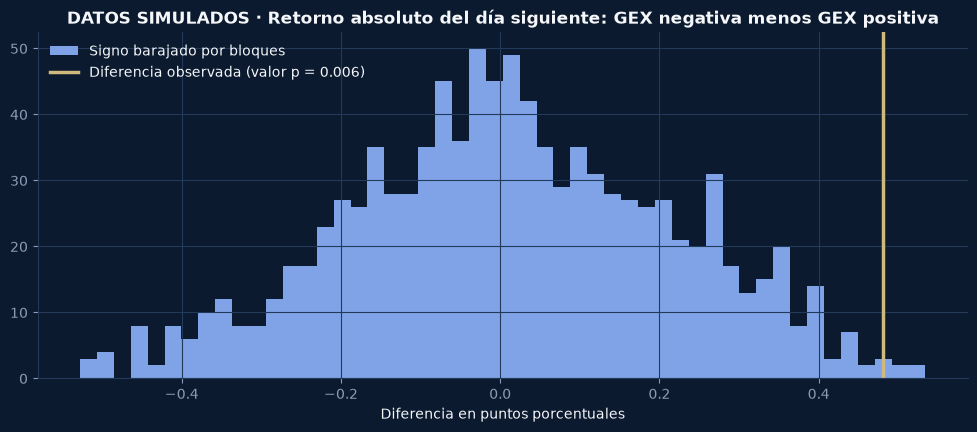

In [50]:
# La diferencia observada contra las diferencias con el signo barajado
plt.hist(diferencias_al_azar * 100, bins=50, color=AZUL, label='Signo barajado por bloques')
plt.axvline(diferencia * 100, color=DORADO, lw=2.5, label=f'Diferencia observada (valor p = {valor_p:.3f})')
plt.title('DATOS SIMULADOS · Retorno absoluto del día siguiente: GEX negativa menos GEX positiva')
plt.xlabel('Diferencia en puntos porcentuales')
plt.legend()
plt.show()

In [51]:
# Para comparar: el mismo cálculo barajando día por día (bloques de 1). Como rompe las rachas, suele dar un valor p más pequeño de lo debido
prueba_de_regimen(signo, retorno_abs, no_permutaciones=1000, tam_bloque=1)[2]

np.float64(0.001998001998001998)

En esta historia el efecto existe porque lo fabricamos, y con esta semilla la prueba lo detecta. No siempre pasa. Al armar el notebook probamos 30 semillas y en 7 la prueba no bajó de 0,05, aunque el efecto estaba ahí. Cambia `semilla` en `historia_sintetica` y compruébalo.

Con tu registro real no sabes la respuesta de antemano. Para eso es la prueba. Y con 60 días la misma prueba tiene muchísimo menos poder que con 500.

## Prueba B: "el muro aguantó 8 de cada 10 días"
Es la frase típica de un proveedor. Entonces vamos a medir lo mismo: ¿qué tan seguido el máximo del día siguiente queda **por debajo** del call wall?

In [52]:
# El call wall "aguanta" si el máximo del día siguiente no lo supera. El put wall, si el mínimo no lo perfora
prueba = prueba.with_columns(
    (pl.col('high') < pl.col('call_wall')).alias('aguanta_call'),
    (pl.col('low') > pl.col('put_wall')).alias('aguanta_put'),
)
# La tasa de aguante (datos SIMULADOS)
prueba['aguanta_call'].mean(), prueba['aguanta_put'].mean()

(0.8482905982905983, 0.8525641025641025)

La tasa es alta. Y sabemos que en esta historia **los muros no hacen nada**: el precio se generó sin mirarlos.

¿Por qué aguanta entonces? Por la distancia. Un nivel que está lejos del precio "aguanta" casi siempre, sea un muro o un número cualquiera. Imagínate que apuestas a que mañana no va a nevar en Cartagena. Vas a acertar casi siempre, y eso no te vuelve meteorólogo.

Por eso una tasa de aguante sola no prueba nada. Hace falta una **línea base**: un nivel placebo a la misma distancia.

### Primer placebo: el espejo
Un nivel a la misma distancia del precio, pero del otro lado. Para el call wall, el espejo "aguanta" si el mínimo del día siguiente no lo perfora.

In [53]:
# El placebo espejo: la misma distancia proporcional que el call wall, pero del lado de abajo
prueba = prueba.with_columns((pl.col('spot') ** 2 / pl.col('call_wall')).alias('nivel_espejo'))
prueba = prueba.with_columns((pl.col('low') > pl.col('nivel_espejo')).alias('aguanta_espejo'))
# La tasa de aguante del muro y la de su espejo (datos SIMULADOS)
prueba['aguanta_call'].mean(), prueba['aguanta_espejo'].mean()

(0.8482905982905983, 0.8568376068376068)

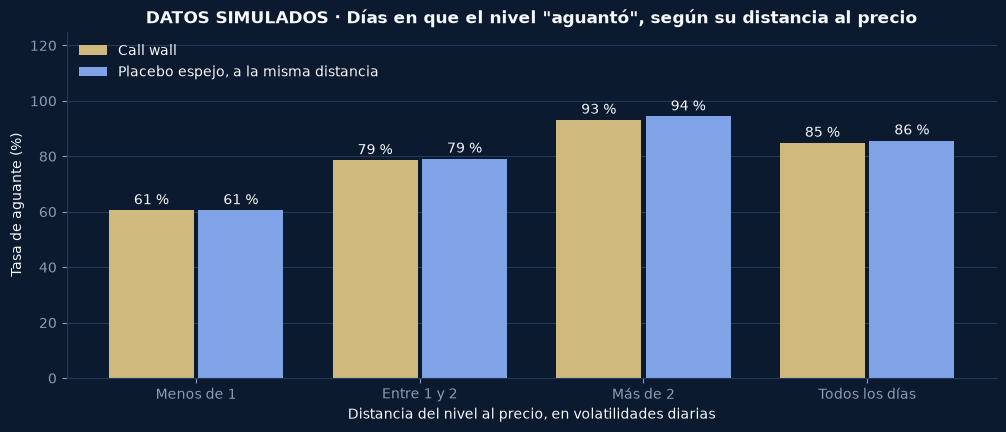

In [54]:
# La tasa de aguante según la distancia: el muro contra su placebo espejo
tramos = [('Menos de 1', 0, 1), ('Entre 1 y 2', 1, 2), ('Más de 2', 2, 99), ('Todos los días', 0, 99)]
tasa_muro, tasa_espejo = [], []
for _, desde, hasta in tramos:
    grupo = prueba.filter((pl.col('dist_call_wall') >= desde) & (pl.col('dist_call_wall') < hasta))
    tasa_muro.append(100 * grupo['aguanta_call'].mean())
    tasa_espejo.append(100 * grupo['aguanta_espejo'].mean())
posicion = np.arange(len(tramos))
barras_muro = plt.bar(posicion - 0.2, tasa_muro, width=0.38, color=DORADO, zorder=2, label='Call wall')
barras_espejo = plt.bar(posicion + 0.2, tasa_espejo, width=0.38, color=AZUL, zorder=2, label='Placebo espejo, a la misma distancia')
plt.bar_label(barras_muro, fmt='%.0f %%', padding=2)
plt.bar_label(barras_espejo, fmt='%.0f %%', padding=2)
plt.xticks(posicion, [t[0] for t in tramos])
plt.ylim(0, 125)
plt.grid(axis='x', visible=False)
plt.title('DATOS SIMULADOS · Días en que el nivel "aguantó", según su distancia al precio')
plt.xlabel('Distancia del nivel al precio, en volatilidades diarias')
plt.ylabel('Tasa de aguante (%)')
plt.legend(loc='upper left')
plt.show()

El muro y su espejo aguantan casi lo mismo. Y entre más lejos están, más aguantan los dos.

El espejo tiene un defecto: compara subidas con bajadas, y en un periodo con tendencia eso no es parejo. Por eso hace falta un segundo placebo, del mismo lado.

### Segundo placebo: la distancia de otro día
Dejamos el nivel arriba del precio, pero le damos la distancia (en volatilidades) que tuvo el muro **en otro día**. Si el muro supiera algo, el nivel puesto en su día debería aguantar más que el mismo nivel puesto en un día cualquiera. Repetimos el barajado 1.000 veces, por bloques, igual que en la prueba A.

In [55]:
def prueba_de_muro(prueba, no_permutaciones=1000, tam_bloque=10, semilla=42):
    """Tasa de aguante del call wall, las tasas de niveles placebo con la distancia de otro día y el valor p."""
    rng = np.random.default_rng(semilla)
    spot, vol, maximo = prueba['spot'].to_numpy(), prueba['vol_diaria'].to_numpy(), prueba['high'].to_numpy()
    distancia = prueba['dist_call_wall'].to_numpy()
    observada = prueba['aguanta_call'].mean()
    # Cada placebo: las mismas distancias, pero repartidas entre los días al azar
    placebos = np.array([(maximo < spot * (1 + permutar_por_bloques(distancia, tam_bloque, rng) * vol)).mean() for _ in range(no_permutaciones)])
    # El valor p: qué fracción de los placebos aguanta igual o más que el muro
    valor_p = (1 + (placebos >= observada).sum()) / (1 + no_permutaciones)
    return observada, placebos, valor_p

In [56]:
# El muro contra 1.000 placebos (datos SIMULADOS)
tasa_call_wall, tasas_placebo, valor_p_muro = prueba_de_muro(prueba)
tasa_call_wall, tasas_placebo.mean(), valor_p_muro

(0.8482905982905983,
 np.float64(0.8489572649572649),
 np.float64(0.5804195804195804))

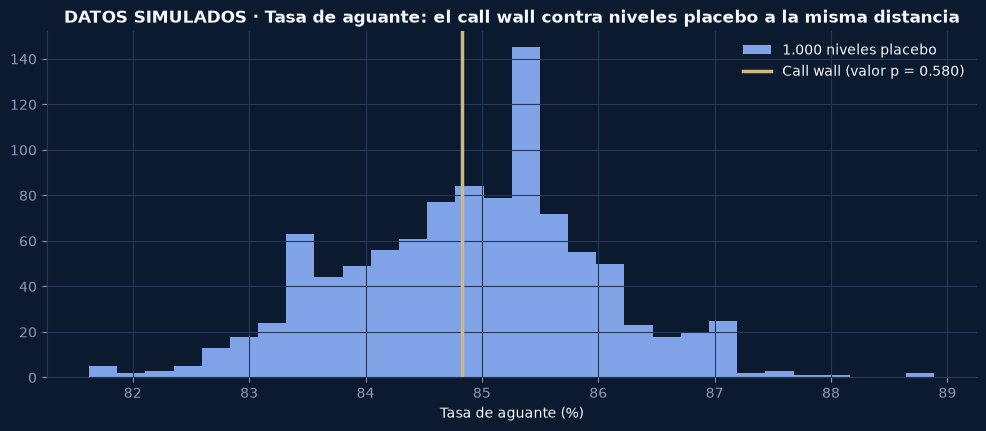

In [57]:
# Mira que la tasa del muro cae en medio de las tasas de los placebos
plt.hist(tasas_placebo * 100, bins=30, color=AZUL, label='1.000 niveles placebo')
plt.axvline(tasa_call_wall * 100, color=DORADO, lw=2.5, label=f'Call wall (valor p = {valor_p_muro:.3f})')
plt.title('DATOS SIMULADOS · Tasa de aguante: el call wall contra niveles placebo a la misma distancia')
plt.xlabel('Tasa de aguante (%)')
plt.legend()
plt.show()

In [58]:
# El resumen de la prueba B (datos SIMULADOS)
pl.DataFrame({
    'nivel': ['call wall', 'placebo espejo', 'placebo distancia de otro día (promedio)'],
    'tasa_de_aguante': [tasa_call_wall, prueba['aguanta_espejo'].mean(), tasas_placebo.mean()],
})

nivel,tasa_de_aguante
str,f64
"""call wall""",0.848291
"""placebo espejo""",0.856838
"""placebo distancia de otro día (promedio)""",0.848957


¿Cuál es la lección? En una historia donde el efecto del muro es **cero**, el muro "aguanta" la mayoría de los días, y los placebos también. La tasa depende de la distancia, no del muro.

Entonces, cuando alguien te muestre "aguantó 8 de cada 10", la pregunta es: **¿comparado con qué?** Con tu registro real la prueba es esta misma. Si el muro no le gana a su placebo, no hay nivel que operar.

Y una advertencia más. Hay varias definiciones de muro, varios vencimientos y varios umbrales. Si pruebas todas las combinaciones, alguna se va a ver bien por pura suerte. Anota cuántas probaste, igual que anotaste cuántos modelos comparaste en la ficha de alfa. ¿Listo?

---
# 8. Conexión con la estrategia
La variable de opciones no reemplaza al modelo. La manera prudente de usarla es como **filtro**: una regla de **cuándo no operar**.

Haz de cuenta que el modelo es el conductor y el filtro es el semáforo. El semáforo no maneja. Solamente dice cuándo esperar.

La estrategia de 12 horas del método ya decide la dirección. Entonces la pregunta nueva es: ¿sus operaciones rinden distinto según el signo de la GEX del día anterior? Si con GEX negativa la estrategia sufre, una regla candidata es no operar esos días. Y esa regla también se prueba contra el azar antes de creerle.

La función que sigue hace el cruce. Exige al menos 60 días de registro. Con menos, cualquier diferencia es ruido.

In [59]:
def operaciones_por_regimen(velas_12h, diario, min_dias=60):
    """Operaciones de la estrategia de 12 horas, cada una con el signo de la GEX registrado el día anterior."""
    if len(diario) < min_dias:
        print(f'Tienes {len(diario)} días de registro y hacen falta {min_dias}. Sigue guardando la foto diaria')
        return None
    # El modelo del Notebook 1 y sus variables (rezagos 1 y 3)
    modelo = models.load_model('model_weights.pth')
    target = 'close_log_return'
    features = [f'{target}_lag_1', f'{target}_lag_3']
    # Los retornos, los rezagos, la predicción y el resultado de cada operación, igual que en el Notebook 2
    trades = research.add_log_return_features(velas_12h, 'close', 1, max_no_lags=3).drop_nulls()
    trades = research.add_trade_log_returns(research.add_model_predictions(trades, modelo, features))
    # La fila del día t se usa en las velas del día t + 1: nunca en velas anteriores a la foto
    senal = diario.select((pl.col('timestamp').dt.date() + pl.duration(days=1)).alias('fecha'), 'signo_gex')
    return trades.with_columns(pl.col('datetime').dt.date().alias('fecha')).join(senal, on='fecha').sort('datetime')

In [60]:
# Con poquitos días la función no entrega nada
operaciones_por_regimen(velas_12h_sim, diario_sim.head(20))

Tienes 20 días de registro y hacen falta 60. Sigue guardando la foto diaria


### Demostración con la historia SIMULADA
El precio simulado es puro azar, así que acá el modelo no tiene ninguna ventaja que filtrar. La demostración sirve para ver el procedimiento, no un resultado.

In [61]:
# Las operaciones de la estrategia sobre las velas SIMULADAS, con el signo de la GEX del día anterior
trades_sim = operaciones_por_regimen(velas_12h_sim, diario_sim)
trades_sim.select('datetime', 'close_log_return', 'y_hat', 'dir_signal', 'trade_log_return', 'signo_gex')

datetime,close_log_return,y_hat,dir_signal,trade_log_return,signo_gex
datetime[μs],f64,f64,f64,f64,i64
2025-07-17 00:00:00,-0.040774,-0.000535,-1.0,0.040774,1
2025-07-17 12:00:00,-0.015211,0.000704,1.0,-0.015211,1
2025-07-18 00:00:00,0.025417,0.000563,1.0,0.025417,-1
2025-07-18 12:00:00,-0.001365,-0.000522,-1.0,0.001365,-1
2025-07-19 00:00:00,-0.01724,0.000055,1.0,-0.01724,-1
…,…,…,…,…,…
2026-11-24 12:00:00,-0.064303,-0.000007,-1.0,0.064303,-1
2026-11-25 00:00:00,-0.024542,0.000843,1.0,-0.024542,-1
2026-11-25 12:00:00,0.018903,0.00097,1.0,0.018903,-1


In [62]:
# Cómo les fue a las operaciones según el signo de la GEX (datos SIMULADOS)
factor_anual = research.sharpe_annualization_factor('12h', 365, 24)
trades_sim.group_by('signo_gex').agg(
    pl.len().alias('operaciones'),
    (pl.col('trade_log_return') > 0).mean().alias('tasa_de_acierto'),
    pl.col('trade_log_return').mean().alias('ev'),
    (pl.col('trade_log_return').mean() / pl.col('trade_log_return').std() * factor_anual).alias('sharpe'),
).sort('signo_gex')

signo_gex,operaciones,tasa_de_acierto,ev,sharpe
i64,u32,f64,f64,f64
-1,476,0.472689,-0.000448,-0.589032
1,520,0.494231,0.000611,0.965928


In [63]:
# ¿La diferencia de EV entre regímenes le gana al azar? La misma prueba de la sección 7, en bloques de 20 velas (10 días)
# Acá no anunciamos de antemano en qué régimen rinde más la estrategia, así que la prueba es a dos colas
diferencia_ev, _, valor_p_filtro = prueba_de_regimen(trades_sim['signo_gex'].to_numpy(), trades_sim['trade_log_return'].to_numpy(), tam_bloque=20, dos_colas=True)
diferencia_ev, valor_p_filtro

(np.float64(-0.0010583036762620566), np.float64(0.3676323676323676))

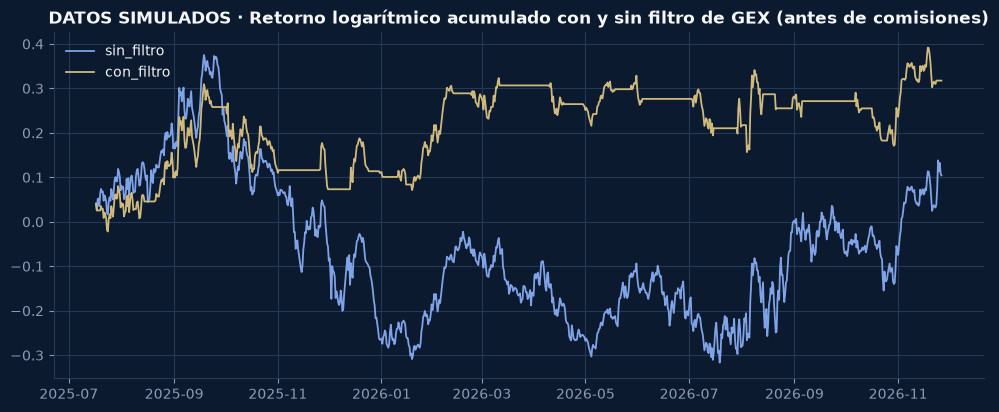

In [64]:
# Una regla candidata: no operar cuando la GEX del día anterior fue negativa
trades_sim = trades_sim.with_columns(
    pl.col('trade_log_return').cum_sum().alias('sin_filtro'),
    pl.when(pl.col('signo_gex') > 0).then(pl.col('trade_log_return')).otherwise(0.0).cum_sum().alias('con_filtro'),
)
research.plot_multiple_lines(trades_sim, ['sin_filtro', 'con_filtro'], 'DATOS SIMULADOS · Retorno logarítmico acumulado con y sin filtro de GEX (antes de comisiones)')

Con la semilla que trae el notebook, la curva con filtro termina más arriba. Y sabemos que es ruido, porque el precio simulado es puro azar. El valor p lo dice: una diferencia de ese tamaño aparece seguido barajando el signo.

Al fin y al cabo, una curva que se ve mejor no basta. Si el valor p no es pequeño, la diferencia entre regímenes cabe dentro del azar y el filtro no se ha ganado su lugar.

### Con tus datos
Cuando tengas 60 días o más de registro, el mismo cruce se hace con velas reales **posteriores al inicio de tu registro**. Son datos que ningún modelo del método ha visto. ¿Listo?

In [65]:
# Cuando tengas tu registro, quita los numerales de estas líneas:
# diario_real = pl.read_csv(RUTA_DIARIO, try_parse_dates=True)
# velas_recientes = pl.read_csv('BTCUSDT_12h_ohlc.csv', try_parse_dates=True).sort('datetime')   # actualízalo con el Notebook 1
# trades_reales = operaciones_por_regimen(velas_recientes, diario_real)

In [66]:
# fin del notebook
# calculamos la foto (GEX, muros, gamma flip), la volvimos una fila con fecha y hora, y vimos cómo se prueba
# lo que falta no se puede simular: la historia real. Esa la construyes tú, una filita por día

---
## Preguntas
1. El interés abierto dice cuántos contratos hay, no quién los tiene. ¿Qué supone la fórmula de GEX para ponerle signo? ¿Por qué ese supuesto puede fallar en bitcoin?
2. En la foto del notebook, ¿el call wall por gamma y el call wall por interés abierto cayeron en el mismo strike? Explica la diferencia con el tiempo al vencimiento.
3. Un proveedor publica que su put wall "aguantó" 9 de cada 10 días. ¿Qué dato le pedirías antes de creerle? ¿Cómo armarías el placebo?
4. Tomas la foto a las 09:00 UTC. ¿Cuál es la primera vela de 12 horas en la que puedes usar esa fila sin sesgo de anticipación? ¿Qué pasaría en tu backtest si la usaras en la vela que abrió a las 00:00 UTC de ese mismo día?
5. En la prueba A barajamos el signo por bloques de 10 días y no día por día. ¿Qué problema evita eso? ¿Qué le pasa al valor p si no lo haces?

## Tu entregable
1. **Empieza hoy el registro.** Cambia `FUENTE = 'deribit'`, corre el notebook y confirma que se guardó una fila en `castle_labs/datos/opciones_diario.csv`. Repítelo todos los días a la misma hora, después de las 08:00 UTC.
2. **Si la descarga falla,** lee el mensaje: dice qué campos llegaron. Cópialo y tráelo, porque los nombres de los campos no se verificaron contra la API real.
3. **Escribe tu hipótesis antes de mirar resultados.** Una línea, con dirección y medida. Por ejemplo: "con GEX negativa el día anterior, el rango de BTC del día siguiente es mayor". Ponle fecha.
4. **Trae al 1 a 1 tus dos semanitas de filas** (el archivo `opciones_diario.csv`) y tu hipótesis escrita. Con dos semanas aún no se prueba nada: se revisa que el registro esté limpio.
5. No operes el nivel. Hasta que tu registro pase la prueba contra el placebo, el muro es un dato que se anota, no una señal.

Al fin y al cabo, el muro no es un nivel mágico, sino una variable más que toca probar. Esa es la idea.

> **Aviso.** Material educativo. No es asesoría financiera ni una recomendación de inversión. Los resultados de las secciones 7 y 8 son simulaciones con datos inventados y no dicen nada sobre el mercado. Ningún resultado pasado o simulado garantiza resultados futuros.